## Test Grid SANOS



In [ ]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.grid.fitter

from quantdata.dysanos.simple.aec import load_data
data = load_data(["SPX"]).data['SPX']
print(f"/done; columns {data.keys()}")



00: Importing torch...done; this took 0.00763ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.31s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.35s.
/done; columns dict_keys(['dates', 'ask_pure_delta', 'ask_pure_dk', 'ask_pure_gamma', 'ask_pure_price', 'ask_pure_theta', 'ask_pure_vega', 'ask_vol', 'bid_pure_delta', 'bid_pure_dk', 'bid_pure_gamma', 'bid_pure_price', 'bid_pure_theta', 'bid_pure_vega', 'bid_vol', 'call_ask', 'call_bid', 'df', '

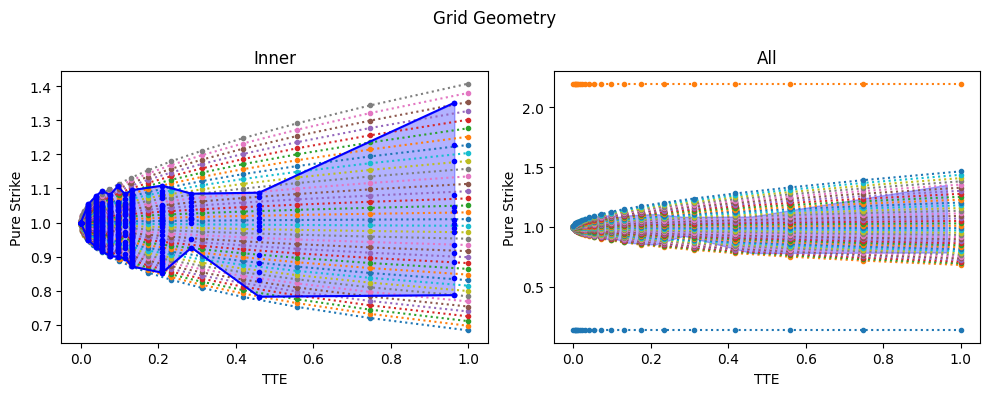

00: Solving for implied DLVs (squared) for 452 options. Mean half spread is 3.0155e-04... done with relative excess error conditional mean 2.4791e+00, std 3.6759e+00, 95th percentile 9.8918e+00, 99th percentile 1.7724e+01, 99.9th percentile 2.0096e+01 and max 2.0385e+01. This took 0.16s.
00: Computing DLV squared's... done; this tool 1.04ms.


/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/grid/fitter.py:451: RuntimeWarning: divide by zero encountered in divide


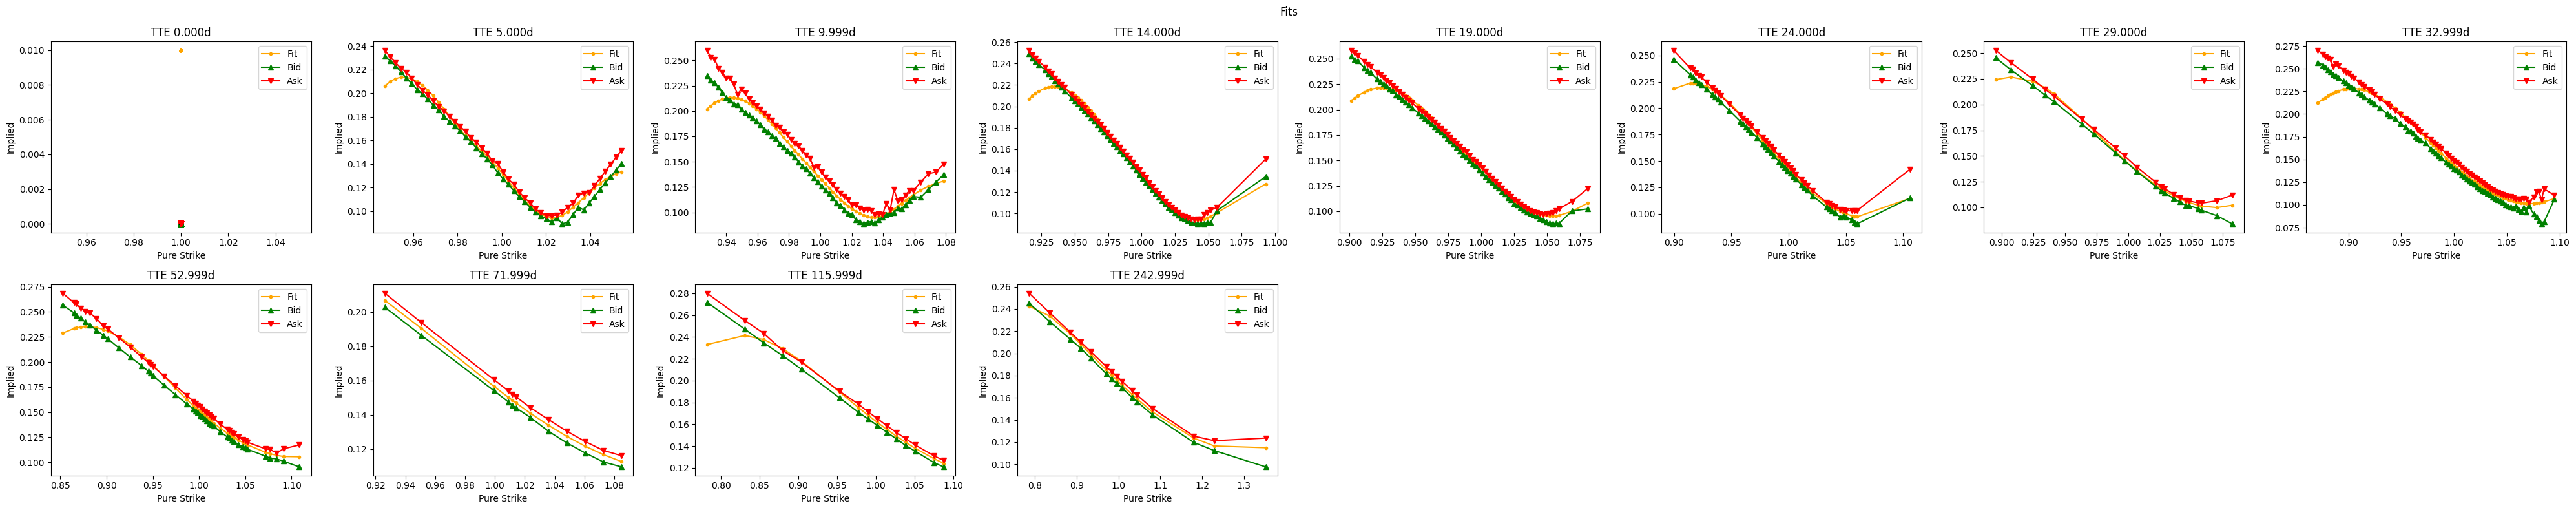

In [ ]:
%aimport quantdata.sanos.grid
%aimport quantdata.sanos.grid.fitter

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.sanos.grid import GridGeometry, GridSanos
from quantdata.sanos.grid.fitter import Eps, Fitter
import numpy as np

def fit(data):
    num_samples = len(data.dates)

    grid        = GridGeometry.create_grid_nms(
                            horizon_t = 1., 
                            num_times = 20,
                            nms_range = (-4,4),
                            num_nms   = 40,
                            dlv_min   = 0.01,
                            dlv_max   = 5.,
                            fwdvol_min       = 0.01,
                            vol_interp = "sqrt_lin_vol",
                            lower_scale = 0.2,
                            upper_scale = 1.5,
                            dtype = np.float64
            )

    eps         = Eps()
    fitter      = Fitter( geometry = grid, eps = eps, debug=True, max_error = None, mid_fit_weight = 1. )
    sanos       = GridSanos( grid )

    def fit_sample( isample, store ):

        strikes    = data.pure_strike[isample,:]
        tte_y      = data.tte_y[isample,:]

        with figure("Grid Geometry", col_size=5, row_size=4, columns=None ) as fig_strikes:
            axD, axA    = fig_strikes.add_subplots("Inner", "All")
            axD.set_xlabel("TTE")
            axA.set_xlabel("TTE")
            axD.set_ylabel("Pure Strike")
            axA.set_ylabel("Pure Strike")

            for i in range(grid.N+2):
                axA.plot( grid.xexpiries, grid.xstrikes[:,i], ".:")
                if i>0 and i<grid.N-1:  
                    axD.plot( grid.xexpiries, grid.xstrikes[:,i], ".:" )
                    
            fig_strikes.render()
            store = fig_strikes.store()

            def plot_strikes(store):
                utty, inv = np.unique(tte_y, return_inverse=True)

                min_strike = np.full(len(utty), np.inf, dtype=strikes.dtype)
                max_strike = np.full(len(utty), -np.inf, dtype=strikes.dtype)

                np.minimum.at(min_strike, inv, strikes)
                np.maximum.at(max_strike, inv, strikes)
            
                store.clear()
                store += axA.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")
                store += axD.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")            
                store += axD.plot(utty, min_strike, ".-", color="blue")
                store += axD.plot(utty, max_strike, ".-", color="blue")
                store += axD.plot(tte_y, strikes, ".", color="blue")
                fig_strikes.render()

                return utty, min_strike, max_strike

            plot_strikes(store)

        utte_y     = np.unique(tte_y)
        opt_interp = grid.time_interpolation_weights( utte_y )
        vols       = np.full( (grid.T,), 0.01, dtype=np.float64 )        

        with figure("Interpolation", col_size=5, row_size=4, columns=None ) as fig_interp:
            ax = fig_interp.add_subplot("Interpolation Weights")
            ax.set_xlabel("TTE")
            ax.set_ylabel("Weight")

            for i in range(grid.N):
                ax.plot(utte_y, opt_interp[:,i], ".-", label=f"DLV {grid.dlv(i):.3f}")
            ax.legend()




        dlvsqs, fit_prices, densities = \
            fitter( fwd_vols     = np.full( (grid.T,), 0.01, dtype=np.float64 ),
                    opt_strikes  = strikes,
                    opt_bid      = data.bid_pure_price[isample,:],
                    opt_ask      = data.ask_pure_price[isample,:],
                    opt_tte      = data.tte_y[isample,:],
                    opt_is_calls = None,
                    opt_mask     = data.is_valid[isample,:],
                    return_only_dlvsqs = False,
                    verbose      = Context.all ) 
            
        assert fit_prices.shape == strikes.shape, f"Expected fit_prices to have shape {strikes.shape}, got {fit_prices.shape}"
        fit_vols = bs.implied(strikes, fit_prices, sqrtT = np.sqrt(tte_y) )

        with figure("Fits", col_size=5, row_size=4, columns=8 ) as fig_fits:

            uttys = np.unique(data.tte_y[isample,:])

            for utty in uttys:
                mask = data.tte_y[isample,:] == utty
                ax = fig_fits.add_subplot(f"TTE {utty*DAYS_PER_YEAR:.3f}d")
                ax.set_xlabel("Pure Strike")
                ax.set_ylabel("Implied")

                ifit = fit_prices[mask]
                istrike = strikes[mask]
                ivol = fit_vols[mask]
                bid_vol = data.bid_vol[isample,mask]
                ask_vol = data.ask_vol[isample,mask]
                bid = data.bid_pure_price[isample,mask]
                ask = data.ask_pure_price[isample,mask]

                if True:
                    ax.plot(istrike, ivol, ".-", color="orange", label="Fit")
                    ax.plot(istrike, bid_vol, "^-", color="green", label="Bid")
                    ax.plot(istrike, ask_vol, "v-", color="red", label="Ask")
                else:
                    ax.plot(istrike, ifit, ".-", color="orange", label="Fit")
                    ax.plot(istrike, bid, "^-", color="green", label="Bid")
                    ax.plot(istrike, ask, "v-", color="red", label="Ask")
                ax.legend()

    fit_sample(0, store)

fit(data)
